# **Import Library**

In [1]:
# Install library yang dibutuhkan 
!pip install split-folders
!pip install -q tensorflowjs --no-deps
!pip install -q tf_keras tensorflow_hub six importlib_resources jax jaxlib "setuptools<81"
!pip install -q tf2onnx onnx onnxruntime

import os
import zipfile
import shutil
import splitfolders
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.preprocessing import image

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from google.colab import files 
import random

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 77.2 MB/s eta 0:00:00


# **Data Preparation**

## **Config Output**

In [2]:
# Path output
OUTPUT_DIR = '/kaggle/working/outputs'
FIG_DIR    = os.path.join(OUTPUT_DIR, 'figures')      # gambar (.png)
DF_DIR     = os.path.join(OUTPUT_DIR, 'dataframes')   # dataframe (.csv)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(DF_DIR, exist_ok=True)

def save_fig(name, dpi=200):
    """Simpan figure matplotlib aktif ke FIG_DIR. Panggil SEBELUM plt.show()."""
    path = os.path.join(FIG_DIR, f'{name}.png')
    plt.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
    print(f'Gambar tersimpan di {path}')
    return path

def save_df(frame, name, index=False):
    """Simpan DataFrame ke DF_DIR sebagai CSV (UTF-8)."""
    path = os.path.join(DF_DIR, f'{name}.csv')
    frame.to_csv(path, index=index, encoding='utf-8')
    print(f'Dataframe tersimpan di {path}  ({len(frame)} baris)')
    return path

## **Data Loading**

In [3]:
import os

# Dataset path dari Kaggle Input
base_dir = '/kaggle/input/datasets/sponishflea/classification-of-skin-diseases/train' 

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Membuat DataFrame 1 gambar (path + label dari nama folder)
paths = sorted(p for p in Path(base_dir).glob('*/*') if p.suffix.lower() in IMG_EXTS)
df = pd.DataFrame({
    'filepath': [str(p) for p in paths],
    'label'   : [p.parent.name for p in paths],
})

# Mapping label ke index 
class_names  = sorted(df['label'].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
df['label_id'] = df['label'].map(class_to_idx).astype('int32')
classes = class_names

# Stratified split 70% Train / 15% Val / 15% Test
train_df, remainder_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df['label_id']
)
val_df, test_df = train_test_split(
    remainder_df, test_size=0.50, random_state=42, stratify=remainder_df['label_id']
)

# Reset Index
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

print(f"Classes: {class_names}\n")
print(f"Total: {len(df)} | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")

# Distribusi gambar per kelas di tiap split
summary = pd.concat(
    {'total': df['label'].value_counts(),
     'train': train_df['label'].value_counts(),
     'val'  : val_df['label'].value_counts(),
     'test' : test_df['label'].value_counts()},
    axis=1).loc[class_names]
display(summary)

# Simpan dataframe hasil data loading & split
save_df(df,       'dataset_full')
save_df(train_df, 'split_train')
save_df(val_df,   'split_val')
save_df(test_df,  'split_test')
save_df(summary.rename_axis('label'), 'class_distribution_summary', index=True)
save_df(pd.DataFrame({'label': class_names, 'label_id': range(len(class_names))}), 'class_mapping')

Classes: ['acne', 'eksim', 'herpes', 'panu', 'rosacea']

Total: 1494 | Train: 1045 | Val: 224 | Test: 225



,total,train,val,test
label,,,,
acne,300,210,45,45
eksim,297,207,45,45
herpes,300,210,45,45
panu,297,208,44,45
rosacea,300,210,45,45


Dataframe tersimpan di /kaggle/working/outputs/dataframes/dataset_full.csv  (1494 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/split_train.csv  (1045 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/split_val.csv  (224 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/split_test.csv  (225 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/class_distribution_summary.csv  (5 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/class_mapping.csv  (5 baris)


'/kaggle/working/outputs/dataframes/class_mapping.csv'

## **Eksplorasi Dataset**

Gambar tersimpan di /kaggle/working/outputs/figures/01_sample_images_per_class.png


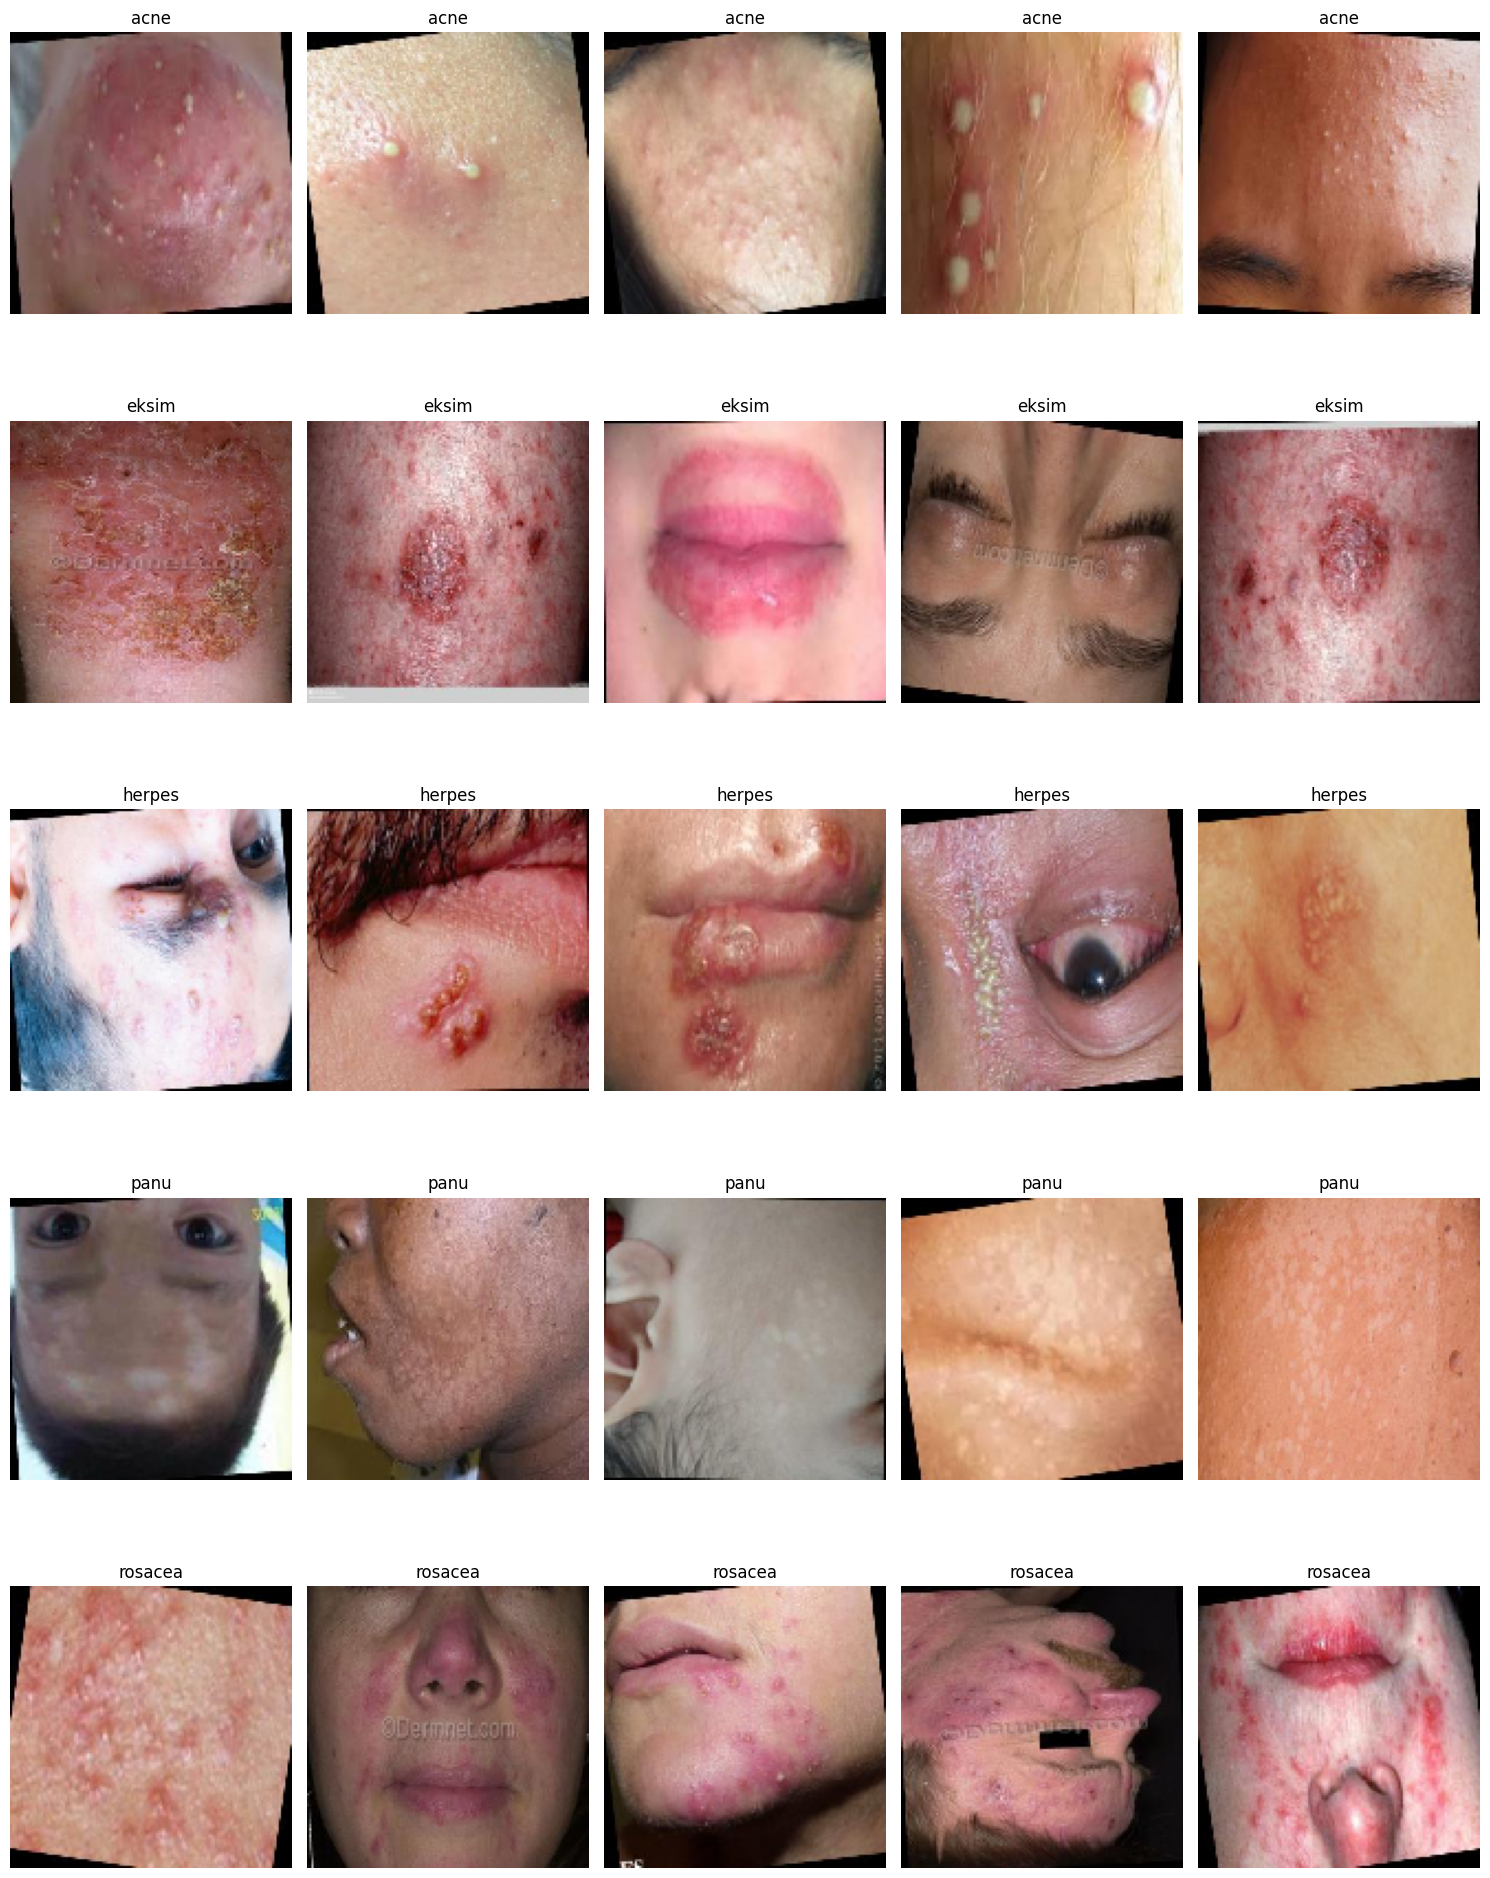

In [4]:
plt.figure(figsize=(15, 20))
index = 1

for cls in classes:
    class_path = os.path.join(base_dir, cls)
    images = [f for f in os.listdir(class_path) if os.path.splitext(f)[1].lower() in IMG_EXTS]
    samples = random.sample(images, 5)

    for img_name in samples:
        img_path = os.path.join(class_path, img_name)
        img = load_img(img_path, target_size=(128,128))
        plt.subplot(len(classes), 5, index)
        plt.imshow(img)
        plt.axis("off")
        plt.title(cls)
        index += 1
        
plt.tight_layout()
save_fig('01_sample_images_per_class')
plt.show()

Gambar tersimpan di /kaggle/working/outputs/figures/02_train_class_distribution.png


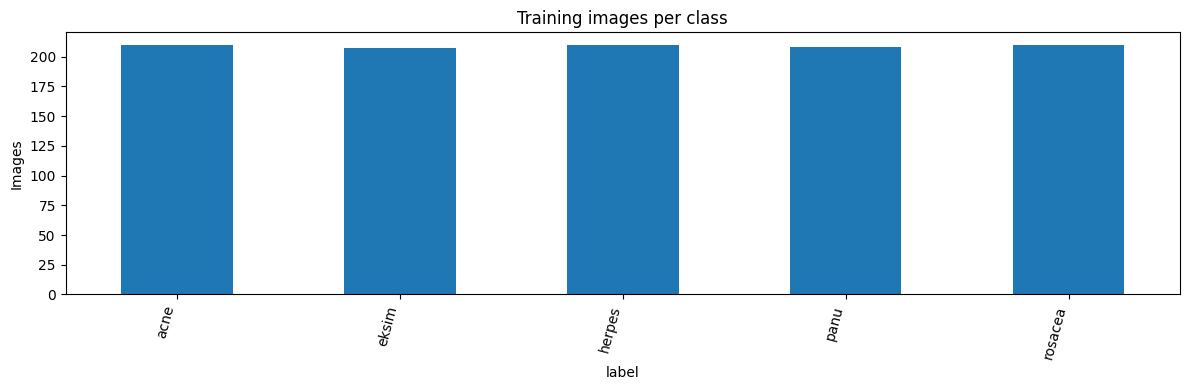

In [5]:
counts = train_df['label'].value_counts().reindex(class_names)
plt.figure(figsize=(12, 4))
counts.plot(kind='bar')
plt.title('Training images per class')
plt.ylabel('Images')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
save_fig('02_train_class_distribution')
plt.show()

# **Data Preprocessing**

## **Make Dataset**

In [6]:
import keras
from keras import layers

AUTOTUNE    = tf.data.AUTOTUNE
num_classes = len(class_names)

def load_image(path, label):
    """Baca file, decode, dan resize."""
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224), antialias=True)           
    return img, label


def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame['filepath'].to_numpy(dtype=str),
        frame['label_id'].to_numpy(dtype='int32'),
    ))
    if training:
        # Shuffle
        ds = ds.shuffle(len(frame), seed=42, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(32)
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, num_classes)),
                num_parallel_calls=AUTOTUNE)
    
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

print(train_ds.element_spec)

I0000 00:00:1792486889.918412      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792486889.923197      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))


# **Modelling**

## **Frozen Backbone**

In [7]:
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Augmentasi data
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(30 / 360, fill_mode='nearest'),   # +-30 derajat
    layers.RandomShear(x_factor=0.2, fill_mode='nearest'),
    layers.RandomZoom(0.2, fill_mode='nearest'),
], name='data_augmentation')


# Load Pre-trained Model (MobileNetV3 Small)
base_model = MobileNetV3Small(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    include_preprocessing=True)

# Freeze bobot base_model agar tidak ikut ditraining ulang
base_model.trainable = False

# Build Model
inputs = keras.Input(shape=(224, 224, 3), name='input_image')
x = data_augmentation(inputs)
x = base_model(x, training=False)   
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax', name='classifier')(x)  # Layer klasifikasi akhir

model = keras.Model(inputs, outputs, name='skin_diseases_mobilenetv3small')
model.summary()

# Compile Model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Callbacks
early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1)

os.makedirs('/kaggle/working/checkpoints', exist_ok=True)
ckpt_phase1 = ModelCheckpoint(
    filepath='/kaggle/working/checkpoints/best_phase1_transfer.keras',
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1)

# Training Model 
history = model.fit(
    train_ds,
    epochs=50, 
    validation_data=val_ds,
    verbose=1,
    callbacks=[early_stop, ckpt_phase1]
)

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "skin_diseases_mobilenetv3small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 5)              │         2,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 942,005 (3.59 MB)

 Trainable params: 2,885 (11.27 KB)

 Non-trainable params: 939,120 (3.58 MB)

Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.2058 - loss: 1.9278
Epoch 1: val_accuracy improved from None to 0.35268, saving model to /kaggle/working/checkpoints/best_phase1_transfer.keras

Epoch 1: finished saving model to /kaggle/working/checkpoints/best_phase1_transfer.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 676ms/step - accuracy: 0.2411 - loss: 1.7908 - val_accuracy: 0.3527 - val_loss: 1.4896
Epoch 2/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3621 - loss: 1.4931
Epoch 2: val_accuracy improved from 0.35268 to 0.50893, saving model to /kaggle/working/checkpoints/best_phase1_transfer.keras

Epoch 2: finished saving model to /kaggle/working/checkpoints/best_phase1_transfer.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.3713 - loss: 1.4600 - val_accuracy: 0.5089 - val_loss: 1.2982
Epoch 3/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4328 - loss: 1.3187
Epoch 3: val_accuracy improved from 0.50893 to 0.54018, saving model to /kaggle

## **Fine-Tuning**

In [8]:
# Fine-tuning 
N_UNFREEZE = 20   # jumlah layer terakhir base_model yang ikut dilatih

base_model.trainable = True
for layer in base_model.layers[:-N_UNFREEZE]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(1 for l in base_model.layers if l.trainable)
print(f"Layer base_model yang dilatih: {n_trainable} dari {len(base_model.layers)}")

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

early_stop_ft = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1)

ckpt_phase2 = ModelCheckpoint(
    filepath='/kaggle/working/checkpoints/best_phase2_finetune.keras',
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1)

history_ft = model.fit(
    train_ds,
    epochs=50,
    validation_data=val_ds,
    verbose=1,
    callbacks=[early_stop_ft, ckpt_phase2]
)


Layer base_model yang dilatih: 15 dari 157
Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7700 - loss: 0.6235
Epoch 1: val_accuracy improved from None to 0.83036, saving model to /kaggle/working/checkpoints/best_phase2_finetune.keras

Epoch 1: finished saving model to /kaggle/working/checkpoints/best_phase2_finetune.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 129ms/step - accuracy: 0.7560 - loss: 0.6275 - val_accuracy: 0.8304 - val_loss: 0.5869
Epoch 2/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7879 - loss: 0.5609
Epoch 2: val_accuracy did not improve from 0.83036
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.7789 - loss: 0.5609 - val_accuracy: 0.8125 - val_loss: 0.5704
Epoch 3/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7737 - loss: 0.5500
Epoch 3: val_accuracy did not improve from 0.83036
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.7847 - loss: 0.5381 - val_accuracy: 0.8304 - val_loss: 0.5301
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━

## **Evaluasi**

8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 548ms/step - accuracy: 0.8978 - loss: 0.2520
Test Accuracy: 89.78%
Dataframe tersimpan di /kaggle/working/outputs/dataframes/test_metrics.csv  (1 baris)


,phase,epoch_in_phase,accuracy,loss,val_accuracy,val_loss
0,frozen_backbone,1,0.241148,1.790847,0.352679,1.489643
1,frozen_backbone,2,0.371292,1.460020,0.508929,1.298150
2,frozen_backbone,3,0.465072,1.281522,0.540179,1.191700
3,frozen_backbone,4,0.533971,1.175048,0.616071,1.111561
4,frozen_backbone,5,0.574163,1.083369,0.638393,1.031731
...,...,...,...,...,...,...
89,fine_tuning,43,0.953110,0.111832,0.928571,0.265320
90,fine_tuning,44,0.960766,0.112796,0.928571,0.250968
91,fine_tuning,45,0.962679,0.111100,0.928571,0.247602
92,fine_tuning,46,0.970335,0.109959,0.910714,0.251023


Dataframe tersimpan di /kaggle/working/outputs/dataframes/training_history.csv  (94 baris)
Gambar tersimpan di /kaggle/working/outputs/figures/03_training_curves.png


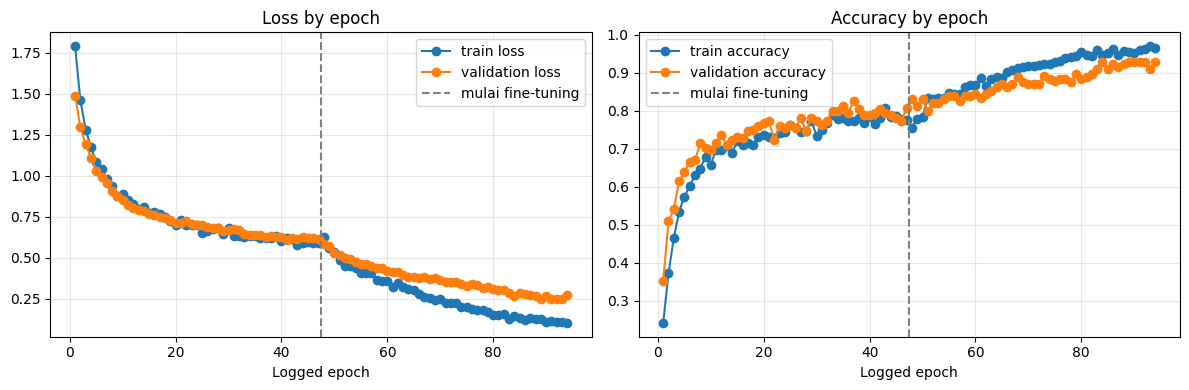

In [9]:
# Evaluasi Test Set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
save_df(pd.DataFrame([{'test_loss': test_loss, 'test_accuracy': test_acc}]), 'test_metrics')

# Mengekstrak history ke DataFrame
history_rows = []
for phase_name, hist in [('frozen_backbone', history), ('fine_tuning', history_ft)]:
    n_rows = len(hist.history.get('loss', []))
    for i in range(n_rows):
        row = {'phase': phase_name, 'epoch_in_phase': i + 1}
        for key, values in hist.history.items():
            row[key] = float(values[i]) if i < len(values) and values[i] is not None else None
        history_rows.append(row)
history_df = pd.DataFrame(history_rows)
display(history_df)
save_df(history_df, 'training_history')

# Plot Akurasi dan Loss 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot Loss
axes[0].plot(history_df.index + 1, history_df['loss'], marker='o', label='train loss')
axes[0].plot(history_df.index + 1, history_df['val_loss'], marker='o', label='validation loss')
axes[0].set_title('Loss by epoch')
axes[0].axvline(len(history.history['loss']) + 0.5, color='gray', ls='--', label='mulai fine-tuning')
axes[0].set_xlabel('Logged epoch')
axes[0].legend()
axes[0].grid(True, alpha=.3)

# Plot Accuracy 
axes[1].plot(history_df.index + 1, history_df['accuracy'], marker='o', label='train accuracy')
axes[1].plot(history_df.index + 1, history_df['val_accuracy'], marker='o', label='validation accuracy')
axes[1].set_title('Accuracy by epoch')
axes[1].axvline(len(history.history['loss']) + 0.5, color='gray', ls='--', label='mulai fine-tuning')
axes[1].set_xlabel('Logged epoch')
axes[1].legend()
axes[1].grid(True, alpha=.3)

plt.tight_layout()
save_fig('03_training_curves')
plt.show()

Menghitung prediksi pada test set
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step

 Classification Report
              precision    recall  f1-score   support

        acne       0.95      0.89      0.92        45
       eksim       0.81      0.87      0.84        45
      herpes       0.92      0.98      0.95        45
        panu       0.88      0.96      0.91        45
     rosacea       0.95      0.80      0.87        45

    accuracy                           0.90       225
   macro avg       0.90      0.90      0.90       225
weighted avg       0.90      0.90      0.90       225

Dataframe tersimpan di /kaggle/working/outputs/dataframes/classification_report.csv  (8 baris)
Dataframe tersimpan di /kaggle/working/outputs/dataframes/test_predictions.csv  (225 baris)

Confusion Matrix
Dataframe tersimpan di /kaggle/working/outputs/dataframes/confusion_matrix.csv  (5 baris)
Gambar tersimpan di /kaggle/working/outputs/figures/04_confusion_matrix.png


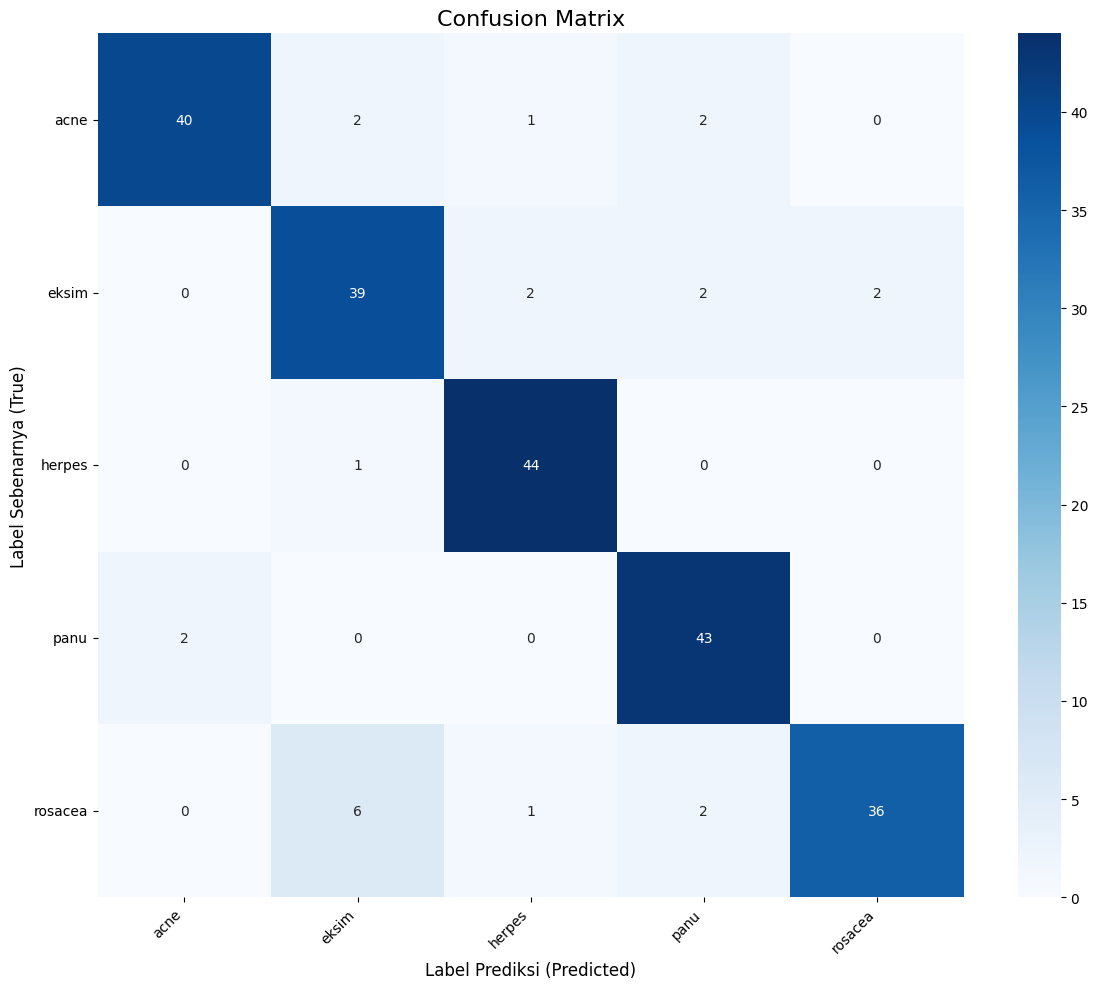

In [10]:
print("Menghitung prediksi pada test set")
# Predict
Y_pred = model.predict(test_ds)

# Mengambil indeks kelas dengan probabilitas tertinggi untuk setiap gambar
y_pred = np.argmax(Y_pred, axis=1)

# Mendapatkan Label Asli
y_true = test_df['label_id'].to_numpy() 

# Mendapatkan nama kelas
target_names = class_names

# Classification Report
print("\n Classification Report")
print(classification_report(y_true, y_pred, target_names=target_names))

# Simpan classification report sebagai DataFrame
report_df = pd.DataFrame(
    classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
).T.rename_axis('class')
save_df(report_df, 'classification_report', index=True)

# Simpan prediksi per gambar pada test set (urutan sama dengan test_df karena test_ds tidak di-shuffle)
pred_df = test_df[['filepath', 'label', 'label_id']].rename(
    columns={'label': 'true_label', 'label_id': 'true_id'}).copy()
pred_df['pred_id']    = y_pred
pred_df['pred_label'] = [target_names[i] for i in y_pred]
pred_df['confidence'] = Y_pred.max(axis=1)
pred_df['correct']    = pred_df['true_id'] == pred_df['pred_id']
save_df(pred_df, 'test_predictions')

# Menampilkan Confusion Matrix
print("\nConfusion Matrix")
cm = confusion_matrix(y_true, y_pred)
save_df(pd.DataFrame(cm, index=target_names, columns=target_names).rename_axis('true_label'),
        'confusion_matrix', index=True)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix', fontsize=16)
plt.ylabel('Label Sebenarnya (True)', fontsize=12)
plt.xlabel('Label Prediksi (Predicted)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
save_fig('04_confusion_matrix')
plt.show()

# **Export Model**

## **Saved Model and tflite**

In [11]:
import json, subprocess, sys

# Folder untuk simpan model
submission_dir  = '/kaggle/working/model'
saved_model_dir = os.path.join(submission_dir, 'saved_model')
tflite_dir      = os.path.join(submission_dir, 'tflite')
tfjs_dir        = os.path.join(submission_dir, 'tfjs_model')
onnx_dir        = os.path.join(submission_dir, 'onnx')
infer_dir       = '/kaggle/working/tmp/saved_model_infer'   # sementara, tidak ikut di-zip

for d in (saved_model_dir, tflite_dir, tfjs_dir, onnx_dir):
    os.makedirs(d, exist_ok=True)

def run_cmd(cmd):
    """Jalankan perintah; jika gagal tampilkan log & hentikan"""
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:]); print(r.stderr[-3000:])
        raise RuntimeError(f'Perintah gagal (exit code {r.returncode})')
    return r

# Simpan ke format SavedModel
model.export(saved_model_dir)
print("Model berhasil disimpan dalam format SavedModel")

# Simpan ke format TF-Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(os.path.join(tflite_dir, 'model.tflite'), 'wb') as f:
    f.write(tflite_model)

# Menyimpan label.txt untuk TFLite
labels = '\n'.join(class_names)
with open(os.path.join(tflite_dir, 'label.txt'), 'w') as f:
    f.write(labels)
print("Model berhasil disimpan dalam format TF-Lite.")

INFO:tensorflow:Assets written to: /kaggle/working/model/saved_model/assets


INFO:tensorflow:Assets written to: /kaggle/working/model/saved_model/assets


Saved artifact at '/kaggle/working/model/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135809792719952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792716112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792719568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792718992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792707856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792710160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712080: TensorSpec(shape=(), dtype=tf.resource, name=None)


INFO:tensorflow:Assets written to: /tmp/tmpg5dsncpe/assets


Saved artifact at '/tmp/tmpg5dsncpe'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135809792707856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792710160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792714384

W0000 00:00:1792487175.919368      23 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792487175.919400      23 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792487176.046246      23 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


## **TensorFlow.js**

In [12]:
# Model khusus inferensi untuk TFJS & ONNX:
# layer augmentasi & dropout dibuang (keduanya tidak aktif saat inferensi), bobot tetap sama.
inf_in  = keras.Input(shape=(224, 224, 3), name='input_image')
h       = base_model(inf_in, training=False)
h       = layers.GlobalAveragePooling2D()(h)
inf_out = model.get_layer('classifier')(h)
export_model = keras.Model(inf_in, inf_out, name='skin_diseases_inference')

shutil.rmtree(infer_dir, ignore_errors=True)
export_model.export(infer_dir)
print("SavedModel khusus inferensi siap dikonversi ke TFJS & ONNX.")

# Konversi ke TensorFlow.js dari SavedModel.
TFJS_RUNNER = (
    "import sys, types; "
    "sys.modules['tensorflow_decision_forests'] = types.ModuleType('tensorflow_decision_forests'); "
    "sys.argv[0] = 'tensorflowjs_converter'; "
    "from tensorflowjs.converters.converter import pip_main; pip_main()"
)

shutil.rmtree(tfjs_dir, ignore_errors=True)
os.makedirs(tfjs_dir, exist_ok=True)

run_cmd([
    sys.executable, '-c', TFJS_RUNNER,
    '--input_format=tf_saved_model',
    '--output_format=tfjs_graph_model',
    '--signature_name=serving_default',
    '--saved_model_tags=serve',
    infer_dir, tfjs_dir,
])

# Validasi hasil + simpan label untuk dipakai di aplikasi web
assert os.path.exists(os.path.join(tfjs_dir, 'model.json')), "model.json tidak terbentuk"
with open(os.path.join(tfjs_dir, 'labels.json'), 'w') as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

print("Model berhasil disimpan dalam format TFJS:", sorted(os.listdir(tfjs_dir)))

INFO:tensorflow:Assets written to: /kaggle/working/tmp/saved_model_infer/assets


INFO:tensorflow:Assets written to: /kaggle/working/tmp/saved_model_infer/assets


Saved artifact at '/kaggle/working/tmp/saved_model_infer'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135809792707856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792710160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792712080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792711504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135809792709200: TensorSpec(shape=(), dtype=tf.resource, name=No

## **ONNX**

In [13]:
# Konversi ke ONNX dari SavedModel
import onnx
import onnxruntime as ort

onnx_path = os.path.join(onnx_dir, 'model.onnx')
run_cmd([
    sys.executable, '-m', 'tf2onnx.convert',
    '--saved-model', infer_dir,
    '--output', onnx_path,
    '--opset', '17',
])

# Validasi struktur model ONNX
onnx.checker.check_model(onnx.load(onnx_path))

# Bandingkan output ONNX vs Keras pada satu batch test set
sess = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
inp_name = sess.get_inputs()[0].name
x_batch, _ = next(iter(test_ds))
x_batch = x_batch.numpy().astype('float32')

onnx_out  = sess.run(None, {inp_name: x_batch})[0]
keras_out = export_model.predict(x_batch, verbose=0)
max_diff  = float(np.abs(onnx_out - keras_out).max())
print(f"Input ONNX : {inp_name} {sess.get_inputs()[0].shape}")
print(f"Selisih maksimum ONNX vs Keras: {max_diff:.2e}")
print("Prediksi sama:", bool((onnx_out.argmax(1) == keras_out.argmax(1)).all()))
if max_diff > 1e-3:
    print("Selisih output cukup besar, periksa hasil konversi.")

# Simpan label bersama model ONNX
with open(os.path.join(onnx_dir, 'label.txt'), 'w') as f:
    f.write('\n'.join(class_names))
print("Model berhasil disimpan dalam format ONNX:", onnx_path)

I0000 00:00:1792487221.315472     147 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Input ONNX : input_image ['unk__949', 224, 224, 3]
Selisih maksimum ONNX vs Keras: 9.24e-06
Prediksi sama: True
Model berhasil disimpan dalam format ONNX: /kaggle/working/model/onnx/model.onnx


In [14]:
# ZIP model yang sudah disimpan (SavedModel, TFLite, TFJS, ONNX)
shutil.make_archive('/kaggle/working/model', 'zip', submission_dir)
shutil.rmtree('/kaggle/working/tmp', ignore_errors=True)
print("Model disimpan: /kaggle/working/model.zip")

Model disimpan: /kaggle/working/model.zip


# **Inference**


Loading TFLite model dari: /kaggle/working/model/tflite/model.tflite

Mencoba prediksi gambar asli dari kelas: eksim


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


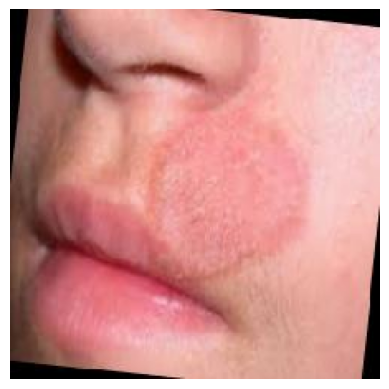

Top 3 Hasil Prediksi:
1. eksim: 99.05%
2. herpes: 0.76%
3. rosacea: 0.18%


In [15]:
# Memuat dan inisialisasi TFLite
tflite_model_path = os.path.join(tflite_dir, 'model.tflite')
label_path = os.path.join(tflite_dir, 'label.txt')

print(f"\nLoading TFLite model dari: {tflite_model_path}")
interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

with open(label_path, 'r') as f:
    labels = [line.strip() for line in f.readlines()]

def predict_with_tflite(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    
    input_data = np.float32(x)
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    
    output_data = interpreter.get_tensor(output_details[0]['index'])
    classes = output_data[0]

    top_3_indices = np.argsort(classes)[-3:][::-1]

    print("Top 3 Hasil Prediksi:")
    for rank, i in enumerate(top_3_indices, start=1):
        predicted_class = labels[i]
        confidence = classes[i] * 100
        print(f"{rank}. {predicted_class}: {confidence:.2f}%")

# Tes Inferensi menggunakan gambar acak dari base_dir
random_class = random.choice(labels)
test_class_dir = os.path.join(base_dir, random_class) 
random_image = random.choice(os.listdir(test_class_dir))
test_image_path = os.path.join(test_class_dir, random_image)

print(f"\nMencoba prediksi gambar asli dari kelas: {random_class}")
predict_with_tflite(test_image_path)

## **Save All Output**

In [16]:
# Rekap file model (format, ukuran) sebagai DataFrame
def folder_size_mb(path):
    if os.path.isfile(path):
        return os.path.getsize(path) / 1e6
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6

model_files_df = pd.DataFrame([
    {'format': 'SavedModel', 'path': saved_model_dir},
    {'format': 'TFLite',     'path': os.path.join(tflite_dir, 'model.tflite')},
    {'format': 'TFJS',       'path': tfjs_dir},
    {'format': 'ONNX',       'path': os.path.join(onnx_dir, 'model.onnx')},
])
model_files_df['size_mb'] = model_files_df['path'].map(lambda p: round(folder_size_mb(p), 2))
display(model_files_df)
save_df(model_files_df, 'exported_models')

# Daftar semua gambar & dataframe yang tersimpan, lalu ZIP agar mudah diunduh
for sub in ('figures', 'dataframes'):
    print(f"\n{sub}/")
    for fn in sorted(os.listdir(os.path.join(OUTPUT_DIR, sub))):
        print('  -', fn)

shutil.make_archive('/kaggle/working/outputs', 'zip', OUTPUT_DIR)
print("\nSemua gambar & dataframe di-ZIP ke: /kaggle/working/outputs.zip")

,format,path,size_mb
0,SavedModel,/kaggle/working/model/saved_model,9.21
1,TFLite,/kaggle/working/model/tflite/model.tflite,3.74
2,TFJS,/kaggle/working/model/tfjs_model,3.90
3,ONNX,/kaggle/working/model/onnx/model.onnx,3.82


Dataframe tersimpan di /kaggle/working/outputs/dataframes/exported_models.csv  (4 baris)

figures/
  - 01_sample_images_per_class.png
  - 02_train_class_distribution.png
  - 03_training_curves.png
  - 04_confusion_matrix.png

dataframes/
  - class_distribution_summary.csv
  - class_mapping.csv
  - classification_report.csv
  - confusion_matrix.csv
  - dataset_full.csv
  - exported_models.csv
  - split_test.csv
  - split_train.csv
  - split_val.csv
  - test_metrics.csv
  - test_predictions.csv
  - training_history.csv

Semua gambar & dataframe di-ZIP ke: /kaggle/working/outputs.zip


In [17]:
# pip freeze requirements.txt